# Willamette → Owasco Lake: primo trasferimento a un’ora

## Risultato
Il filtro scelto sul Willamette **non supera la persistenza** su questa finestra lacustre. La MAE è quasi uguale, leggermente peggiore; gli intervalli esplorativi includono zero. Il filtro modifica soltanto quattro delle 1.275 previsioni accettate. Non è dimostrato un beneficio.

Una sonda superficiale EXO 1, Owasco Lake (New York), 1–29 luglio 2020 UTC, estremi inclusivi. Modello addestrato sul Willamette nel 2024, soglia scelta soltanto sullo sviluppo Willamette e fissata a **0,10 mg/L** prima di leggere le osservazioni lacustri. È una prova retrospettiva di trasferimento spaziale, non una previsione emessa nel 2020.

La spiegazione completa è anche in inglese: `docs/OWASCO_LAKE_TRANSFER_EN.md`.


## Metodo e dati
### 1. Verificare codice, archivi e coorte
Il commit `c06f1a79f073f71764aef501e9ae0f298a775377` precede la prima acquisizione delle misure. Il replay verifica i file correnti contro quel commit, gli hash delle risposte e le identità di serie. Questa integrità non autentica da sola la verità fisica del sensore.

Le due serie DO e temperatura appartengono alla stessa EXO 1. Il catalogo dice “Depth at 3 feet”; lo studio USGS descrive la sonda superficiale a 0,76 m: conserviamo entrambe le etichette, senza affermare una profondità fisica esatta. Nessuna unione con sonde profonde.


In [1]:
from pathlib import Path
import json, sys, math, gzip, hashlib
from html import escape
from IPython.display import display, HTML
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'scripts'))
import lake_transfer as lake
from audit_stability_compare import assert_same_receipt
path=ROOT/'docs/evidence/owasco-lake-transfer/evaluation.json'
r=json.loads(path.read_bytes())
assert_same_receipt(lake.evaluate(ROOT),r)
P,R,C,F=lake.METHODS
labels={P:'Ultima misura',R:'Regressione congelata',C:'Vecchia regola',F:'Filtro 0,10'}
def table(headers,rows):
 display(HTML('<table><thead><tr>'+''.join('<th>'+escape(str(x))+'</th>'for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+escape(str(x))+'</td>'for x in row)+'</tr>'for row in rows)+'</tbody></table>'))
print('Replay offline verificato; SHA256:',hashlib.sha256(path.read_bytes()).hexdigest())
table(['Fonte','Record','Approvati e accettati','Esclusi per qualità'],[[k,v['total'],v['accepted'],len(v['excluded'])]for k,v in r['sourceQuality'].items()])
table(['Controllo del reticolo','Valore'],list(r['fullExpectedGrid'].items()))


Replay offline verificato; SHA256: 7bd27ec609a7c4f471385498b61fff7b9d74546de13711559e84fcb16536ff85


Fonte,Record,Approvati e accettati,Esclusi per qualità
oxygen,2685,2685,0
temperature,2684,2684,0


Controllo del reticolo,Valore
expectedOrigins,1332
acceptedExactGridPairs,1275
missingApprovedOxygenOrigins,44
presentOriginsWithIncompleteHistoryOrTarget,13
acceptedGridFraction,0.9572072072072072


### 2. Distinguere una misura assente sul reticolo da un buco fisico
La frequenza dichiarata è 15 minuti, ma una parte dei timestamp del 27–28 luglio ha minuti non allineati ai quarti d’ora. Conserviamo i timestamp originali. Non spostiamo, arrotondiamo o interpoliamo i dati per recuperare coppie.

Ogni previsione richiede dodici misure esatte ogni 30 minuti e un target esatto a +1 ora. La portata non era un ingresso del modello; il nuovo protocollo lacustre richiede esplicitamente solo DO e temperatura, senza inventare portata zero. Le stesse 1.275 coppie sono usate da tutti i metodi.


In [2]:
from collections import Counter
from datetime import datetime,timedelta
cadence=[]
for name in ('oxygen','temperature'):
 data=json.loads(gzip.decompress((ROOT/f'docs/datasets/owasco-lake-transfer/{name}.json.gz').read_bytes()))
 times=[datetime.fromisoformat(f['properties']['time'].replace('Z','+00:00'))for f in data['features']]
 off=[t for t in times if t.minute%15 or t.second or t.microsecond]
 cadence.append([name,len(times),len(off),dict(Counter(t.date().isoformat()for t in off))])
table(['Fonte','Record','Fuori reticolo quarti d’ora','Date e conteggi'],cadence)
print('44 origini DO mancanti sul reticolo + 13 storie/target incompleti; non equivalgono a 57 buchi fisici.')


Fonte,Record,Fuori reticolo quarti d’ora,Date e conteggi
oxygen,2685,84,"{'2020-07-27': 24, '2020-07-28': 60}"
temperature,2684,82,"{'2020-07-27': 23, '2020-07-28': 59}"


44 origini DO mancanti sul reticolo + 13 storie/target incompleti; non equivalgono a 57 buchi fisici.


## Risultati
### 3. Confrontare gli errori sui medesimi orari
MAE: errore assoluto medio, più piccolo è meglio. Tutti i valori sono in mg/L. Le sei cifre decimali servono alla riproducibilità numerica e non indicano l’accuratezza fisica dello strumento. La RMSE è secondaria e non sostituisce il criterio primario MAE.


Metodo,Coppie,MAE mg/L,RMSE mg/L,Bias mg/L,p95 errore mg/L
Ultima misura,1275,0.038667,0.068428,0.001020,0.100000
Regressione congelata,1275,0.048166,0.067191,-0.007610,0.126924
Vecchia regola,1275,0.047860,0.067450,-0.007378,0.126924
"Filtro 0,10",1275,0.038692,0.068125,0.000842,0.100000


Metodo,Aiuta,Uguale,Peggiora
Regressione congelata,298,0,977
Vecchia regola,279,70,926
"Filtro 0,10",2,1271,2


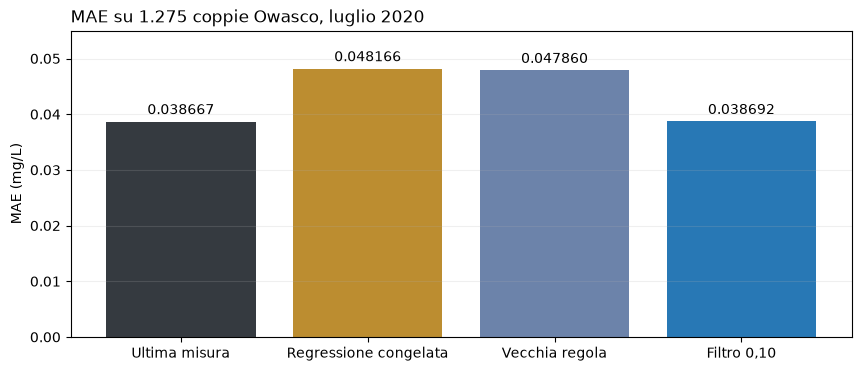

Decisione congelata: no-overall-improvement
Variazione relativa MAE del filtro rispetto alla persistenza: +0.066448%


In [3]:
import matplotlib.pyplot as plt
table(['Metodo','Coppie','MAE mg/L','RMSE mg/L','Bias mg/L','p95 errore mg/L'],[[labels[m],r['scores'][m]['pairs'],*[f"{r['scores'][m][k]:.6f}"for k in ('maeMgL','rmseMgL','biasMgL','p95AbsoluteErrorMgL')]]for m in lake.METHODS])
table(['Metodo','Aiuta','Uguale','Peggiora'],[[labels[m],*[r['pairedCasesAgainstPersistence'][m][k]for k in ('wins','ties','losses')]]for m in (R,C,F)])
fig,ax=plt.subplots(figsize=(8.5,3.6),layout='constrained')
bars=ax.bar([labels[m]for m in lake.METHODS],[r['scores'][m]['maeMgL']for m in lake.METHODS],color=['#353A40','#BC8D30','#6C83AA','#2878B5'])
ax.set_ylim(0,.055);ax.set_ylabel('MAE (mg/L)');ax.set_title('MAE su 1.275 coppie Owasco, luglio 2020',loc='left');ax.grid(axis='y',alpha=.2)
ax.bar_label(bars,labels=[f"{r['scores'][m]['maeMgL']:.6f}"for m in lake.METHODS],padding=3)
plt.show()
print('Decisione congelata:',r['decision'])
print('Variazione relativa MAE del filtro rispetto alla persistenza:',f"{100*(r['scores'][F]['maeMgL']/r['scores'][P]['maeMgL']-1):+.6f}%")


### 4. Controllare l’incertezza e quante previsioni cambiano
Guadagno = errore assoluto della persistenza meno quello del filtro: positivo aiuta. Bootstrap appaiato a blocchi di calendario: 5.000 ricampionamenti, semi e lunghezze fissati prima della cattura. I tre intervalli sono analisi di sensibilità condizionate alla finestra, non conferme indipendenti né intervalli di previsione.

Le quattro righe sotto sono tutte le correzioni applicate dal filtro: due utili e due dannose. Non rappresentano un campione sufficiente per validare la capacità di riconoscere eventi.


In [4]:
table(['Blocco ore','Blocchi non vuoti','Limite inferiore guadagno mg/L','Limite superiore mg/L'],[[b['blockHours'],b['nonemptyBlocks'],f"{b['gainAgainstPersistence'][F]['lowerGainMgL']:+.9f}",f"{b['gainAgainstPersistence'][F]['upperGainMgL']:+.9f}"]for b in r['bootstrap']])
changed=[row for row in r['rows']if row['predictionsMgL'][F]!=row['predictionsMgL'][P]]
table(['Origine UTC','Target UTC','Ultima','Filtro','Osservato','Guadagno errore mg/L'],[[row['origin'],row['target'],f"{row['predictionsMgL'][P]:.6f}",f"{row['predictionsMgL'][F]:.6f}",f"{row['actual']:.6f}",f"{abs(row['predictionsMgL'][P]-row['actual'])-abs(row['predictionsMgL'][F]-row['actual']):+.6f}"]for row in changed])
assert len(changed)==4
table(['Ingresso','Coppie fuori range univariato di training'],list(r['featureExtrapolation']['byFeature'].items()))
print('Coppie con almeno un ingresso fuori range:',r['featureExtrapolation']['pairs'],'/',len(r['rows']))


Blocco ore,Blocchi non vuoti,Limite inferiore guadagno mg/L,Limite superiore mg/L
48,14,-0.000403597,+0.000422240
24,28,-0.000396982,+0.000398638
72,10,-0.000525352,+0.000460663


Origine UTC,Target UTC,Ultima,Filtro,Osservato,Guadagno errore mg/L
2020-07-01T09:30:00.000Z,2020-07-01T10:30:00.000Z,10.000000,9.896630,9.800000,+0.103370
2020-07-01T10:00:00.000Z,2020-07-01T11:00:00.000Z,10.100000,9.999433,9.800000,+0.100567
2020-07-04T08:00:00.000Z,2020-07-04T09:00:00.000Z,10.200000,10.070540,10.200000,-0.129460
2020-07-06T21:30:00.000Z,2020-07-06T22:30:00.000Z,9.600000,9.707236,9.600000,-0.107236


Ingresso,Coppie fuori range univariato di training
oxygenNow,0
oxygenDelta30m,0
oxygenDelta2h,0
oxygenDelta5h30m,0
clockSinUTC,0
clockCosUTC,0
temperatureNow,814
temperatureDelta2h,20


Coppie con almeno un ingresso fuori range: 819 / 1275


### 5. Esempio temporale: prime 48 ore della finestra
La selezione di questo tratto è temporale, non basata sugli errori più favorevoli. Le curve sono allineate al **target**, un’ora dopo l’origine. Il filtro e la persistenza possono sovrapporsi: l’assenza di una linea distinta non significa un dato mancante.


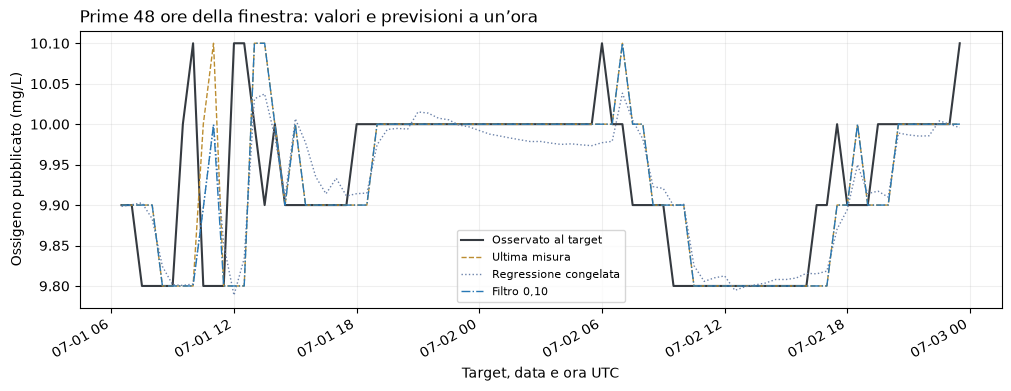

In [5]:
start=datetime.fromisoformat(r['window']['start'].replace('Z','+00:00'))
sample=[row for row in r['rows']if datetime.fromisoformat(row['target'].replace('Z','+00:00'))<start+timedelta(hours=48)]
x=[datetime.fromisoformat(row['target'].replace('Z','+00:00'))for row in sample]
fig,ax=plt.subplots(figsize=(10,3.8),layout='constrained')
ax.plot(x,[row['actual']for row in sample],color='#353A40',label='Osservato al target',linewidth=1.5)
for method,color,style in ((P,'#BC8D30','--'),(R,'#6C83AA',':'),(F,'#2878B5','-.')):
 ax.plot(x,[row['predictionsMgL'][method]for row in sample],color=color,linestyle=style,label=labels[method],linewidth=1)
ax.set_xlabel('Target, data e ora UTC');ax.set_ylabel('Ossigeno pubblicato (mg/L)');ax.set_title('Prime 48 ore della finestra: valori e previsioni a un’ora',loc='left');ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.autofmt_xdate();plt.show()


## Cosa impariamo e limiti
Il filtro elimina gran parte del costo della regressione sul lago, ma qui è quasi sempre la persistenza e **non dimostra un miglioramento** rispetto a quella. Non adattiamo ora la soglia per salvare il test: questa finestra è ormai osservata.

819 coppie su 1.275 hanno almeno un ingresso fuori dai range univariati del training, soprattutto la temperatura. È un segnale di trasferimento fuori dai valori già visti, non una causa dimostrata del risultato o una soglia di affidabilità validata. Nessun target è sotto i 5 mg/L illustrativi: non è validata una capacità di allerta o un beneficio ecologico.

La riduzione del 5,845% nella parte successiva dello sviluppo Willamette resta sviluppo su dati già esaminati; non è il risultato lacustre. Nessuna calibrazione o modifica è stata fatta usando il lago.

Virdacora mantiene la missione di prove ambientali verificabili al servizio delle comunità e dei giovani. Un risultato negativo pubblicato con misure, codice e limiti aiuta a delimitare ciò che il componente numerico sa fare. Nessuna modifica a Oracle operativo, quorum, governance, tesoreria, token o spese automatiche.


In [6]:
assert r['thresholdMgL']==.1 and r['thresholdTunedOnLake'] is False and r['newFit'] is False
assert r['operationalPromotion'] is False and r['decision']=='no-overall-improvement'
assert len(r['rows'])==1275 and r['fullExpectedGrid']['expectedOrigins']==1332
assert all(v['nonfinitePredictions']==0 and v['negativePredictions']==0 for v in r['predictionDiagnostics'].values())
assert all(b['gainAgainstPersistence'][F]['lowerGainMgL']<0<b['gainAgainstPersistence'][F]['upperGainMgL']for b in r['bootstrap'])
print('Risultato negativo e confini della prova verificati.')


Risultato negativo e confini della prova verificati.
